1: Predicting Customer Demand / Cleaning Erroneous Data




In [32]:
!wget -q -O carsales.csv https://bradfordtuckfield.com/carsales.csv

In [33]:
import pandas as pd
carsales=pd.read_csv('carsales.csv')

In [34]:
print(carsales.head())

     Month  Monthly car sales in Quebec 1960-1968
0  1960-01                                 6550.0
1  1960-02                                 8728.0
2  1960-03                                12026.0
3  1960-04                                14395.0
4  1960-05                                14587.0


In [35]:
carsales.columns= ['month','sales']

In [36]:
print(carsales.tail())

                                     month    sales
104                                1968-09  14385.0
105                                1968-10  21342.0
106                                1968-11  17180.0
107                                1968-12  14577.0
108  Monthly car sales in Quebec 1960-1968      NaN


In [37]:
carsales=carsales.loc[0:107,:].copy()
print(carsales.tail())

       month    sales
103  1968-08  16722.0
104  1968-09  14385.0
105  1968-10  21342.0
106  1968-11  17180.0
107  1968-12  14577.0


In [38]:
print(1960+1)
print('1960'+'1')

1961
19601


In [39]:
carsales['period']=list(range(108))

2: Plotting Data to Find Trends

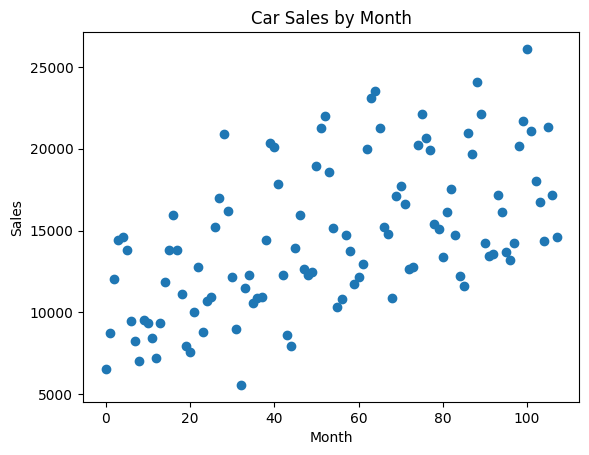

In [40]:
from matplotlib import pyplot as plt
plt.scatter(carsales['period'],carsales['sales'])
plt.title('Car Sales by Month')
plt.xlabel('Month')
plt.ylabel('Sales')
plt.show()

3: Performing Linear Regression

In [41]:
x = carsales['period'].values.reshape(-1,1)
y = carsales['sales'].values.reshape(-1,1)

In [42]:
print(x)
print(y)

[[  0]
 [  1]
 [  2]
 [  3]
 [  4]
 [  5]
 [  6]
 [  7]
 [  8]
 [  9]
 [ 10]
 [ 11]
 [ 12]
 [ 13]
 [ 14]
 [ 15]
 [ 16]
 [ 17]
 [ 18]
 [ 19]
 [ 20]
 [ 21]
 [ 22]
 [ 23]
 [ 24]
 [ 25]
 [ 26]
 [ 27]
 [ 28]
 [ 29]
 [ 30]
 [ 31]
 [ 32]
 [ 33]
 [ 34]
 [ 35]
 [ 36]
 [ 37]
 [ 38]
 [ 39]
 [ 40]
 [ 41]
 [ 42]
 [ 43]
 [ 44]
 [ 45]
 [ 46]
 [ 47]
 [ 48]
 [ 49]
 [ 50]
 [ 51]
 [ 52]
 [ 53]
 [ 54]
 [ 55]
 [ 56]
 [ 57]
 [ 58]
 [ 59]
 [ 60]
 [ 61]
 [ 62]
 [ 63]
 [ 64]
 [ 65]
 [ 66]
 [ 67]
 [ 68]
 [ 69]
 [ 70]
 [ 71]
 [ 72]
 [ 73]
 [ 74]
 [ 75]
 [ 76]
 [ 77]
 [ 78]
 [ 79]
 [ 80]
 [ 81]
 [ 82]
 [ 83]
 [ 84]
 [ 85]
 [ 86]
 [ 87]
 [ 88]
 [ 89]
 [ 90]
 [ 91]
 [ 92]
 [ 93]
 [ 94]
 [ 95]
 [ 96]
 [ 97]
 [ 98]
 [ 99]
 [100]
 [101]
 [102]
 [103]
 [104]
 [105]
 [106]
 [107]]
[[ 6550.]
 [ 8728.]
 [12026.]
 [14395.]
 [14587.]
 [13791.]
 [ 9498.]
 [ 8251.]
 [ 7049.]
 [ 9545.]
 [ 9364.]
 [ 8456.]
 [ 7237.]
 [ 9374.]
 [11837.]
 [13784.]
 [15926.]
 [13821.]
 [11143.]
 [ 7975.]
 [ 7610.]
 [10015.]
 [12759.]
 [ 8816.]
 [1

In [43]:
from sklearn.linear_model import LinearRegression
regressor = LinearRegression()
regressor.fit(x, y)

LinearRegression()

In [44]:
print(regressor.coef_)
print(regressor.intercept_)

[[81.20250174]]
[10250.77726809]


4: Applying Algebra to the Regression Line

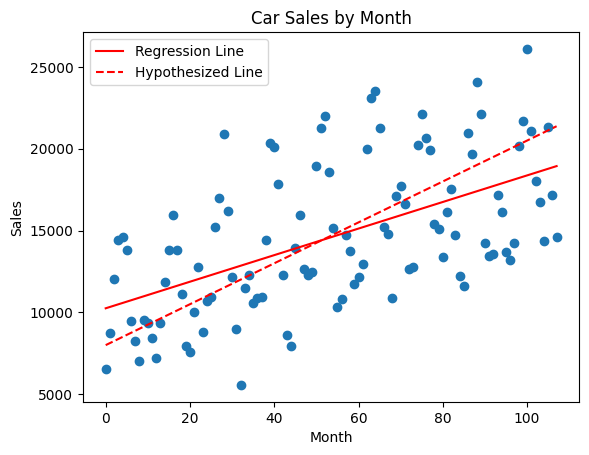

In [45]:
plt.scatter(carsales['period'],carsales['sales'])
plt.plot(carsales['period'],[81.2 * i + 10250.8 for i in carsales['period']],'r-',label='Regression Line')
plt.plot(carsales['period'],[125 * i + 8000 for i in carsales['period']],'r--',label='Hypothesized Line')
plt.legend(loc="upper left")
plt.title('Car Sales by Month')
plt.xlabel('Month')
plt.ylabel('Sales')
plt.show()

5: Calculating Error Measurements

In [46]:
saleslist=carsales['sales'].tolist()
regressionline=[81.2 * i + 10250.8 for i in carsales['period']]
hypothesizedline=[125 * i + 8000 for i in carsales['period']]
error1=[(x-y) for x, y in zip(regressionline,saleslist)]
error2=[(x-y) for x, y in zip(hypothesizedline,saleslist)]

In [47]:
print(error1)
print(error2)

[3700.7999999999993, 1604.0, -1612.800000000001, -3900.6000000000004, -4011.4000000000015, -3134.2000000000007, 1240.0, 2568.199999999999, 3851.3999999999996, 1436.5999999999985, 1698.7999999999993, 2688.0, 3988.199999999999, 1932.3999999999996, -449.40000000000146, -2315.2000000000007, -4376.0, -2189.800000000001, 569.3999999999996, 3818.5999999999985, 4264.799999999999, 1941.0, -721.8000000000011, 3302.3999999999996, 1522.5999999999985, 1333.7999999999993, -2838.0, -4566.800000000001, -8375.6, -3599.4000000000015, 543.7999999999993, 3771.0, 7281.199999999999, 1456.3999999999996, 755.5999999999985, 2509.7999999999993, 2312.0, 2290.199999999999, -1068.6000000000004, -6961.4000000000015, -6629.200000000001, -4236.0, 1393.199999999999, 5100.4, 5861.5999999999985, -27.200000000000728, -1950.0, 1439.199999999999, 1881.3999999999996, 1759.5999999999985, -4633.200000000001, -6867.0, -7541.799999999999, -4026.6000000000004, -539.4000000000015, 4410.799999999999, 4006.0, 127.20000000000073, 12

In [48]:
import numpy as np

error1abs=[abs(value) for value in error1]
error2abs=[abs(value) for value in error2]

print(np.mean(error1abs))
print(np.mean(error2abs))

3154.3592592592595
3239.777777777778


In [49]:
error1squared=[(value)**2 for value in error1]
error2squared=[(value)**2 for value in error2]

print(np.sqrt(np.mean(error1squared)))
print(np.sqrt(np.mean(error2squared)))

3725.491219512759
3968.900519455399


In [50]:
def get_mae(line,actual):
    error=[(x-y) for x,y in zip(line,actual)]
    errorabs=[abs(value) for value in error]
    mae=np.mean(errorabs)
    return(mae)

def get_rmse(line,actual):
    error=[(x-y) for x,y in zip(line,actual)]
    errorsquared=[(value)**2 for value in error]
    rmse=np.sqrt(np.mean(errorsquared))
    return(rmse)

In [51]:
print(get_rmse(regressionline,saleslist))
print(get_rmse(hypothesizedline,saleslist))

3725.491219512759
3968.900519455399


6: Using Regression to Forecast Future Trends

In [52]:
x_extended = np.append(carsales['period'], np.arange(108, 116))

In [53]:
x_extended=x_extended.reshape(-1,1)
extended_prediction=regressor.predict(x_extended)
print(extended_prediction)

[[10250.77726809]
 [10331.97976983]
 [10413.18227157]
 [10494.38477331]
 [10575.58727505]
 [10656.78977679]
 [10737.99227853]
 [10819.19478026]
 [10900.397282  ]
 [10981.59978374]
 [11062.80228548]
 [11144.00478722]
 [11225.20728896]
 [11306.4097907 ]
 [11387.61229243]
 [11468.81479417]
 [11550.01729591]
 [11631.21979765]
 [11712.42229939]
 [11793.62480113]
 [11874.82730287]
 [11956.02980461]
 [12037.23230634]
 [12118.43480808]
 [12199.63730982]
 [12280.83981156]
 [12362.0423133 ]
 [12443.24481504]
 [12524.44731678]
 [12605.64981851]
 [12686.85232025]
 [12768.05482199]
 [12849.25732373]
 [12930.45982547]
 [13011.66232721]
 [13092.86482895]
 [13174.06733068]
 [13255.26983242]
 [13336.47233416]
 [13417.6748359 ]
 [13498.87733764]
 [13580.07983938]
 [13661.28234112]
 [13742.48484286]
 [13823.68734459]
 [13904.88984633]
 [13986.09234807]
 [14067.29484981]
 [14148.49735155]
 [14229.69985329]
 [14310.90235503]
 [14392.10485676]
 [14473.3073585 ]
 [14554.50986024]
 [14635.71236198]
 [14716.91

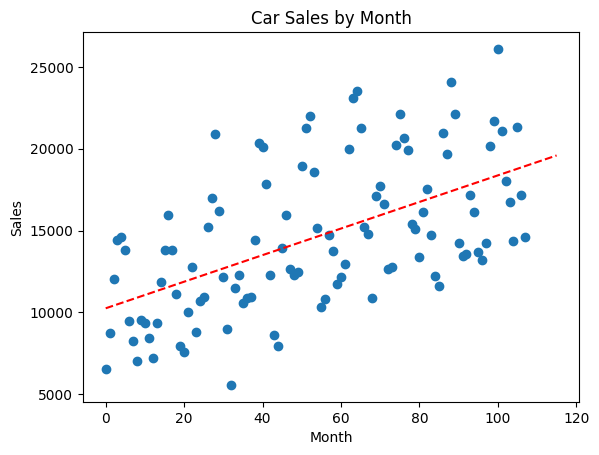

In [54]:
plt.scatter(carsales['period'],carsales['sales'])
plt.plot(x_extended,extended_prediction,'r--')
plt.title('Car Sales by Month')
plt.xlabel('Month')
plt.ylabel('Sales')
plt.show()

7: Trying More Regression Models

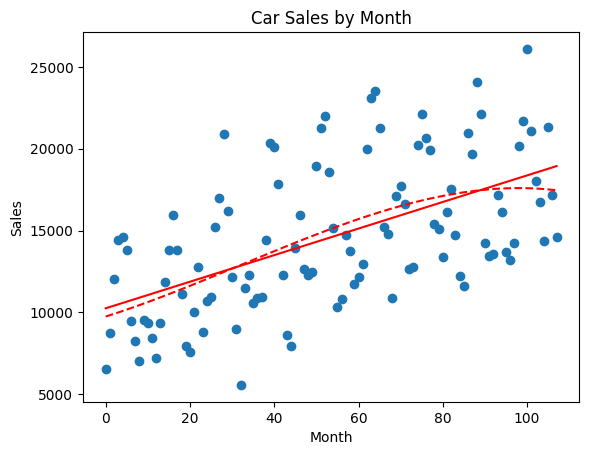

In [55]:
carsales['quadratic']=carsales['period'].apply(lambda x: x**2)
carsales['cubic']=carsales['period'].apply(lambda x: x**3)

x3 = carsales.loc[:,['period','quadratic','cubic']].values.reshape(-1,3)
y = carsales['sales'].values.reshape(-1,1)

regressor_cubic = LinearRegression()
regressor_cubic.fit(x3, y)
plt.scatter(carsales['period'],carsales['sales'])
plt.plot(x,regressor.predict(x),'r-')
plt.plot(x,regressor_cubic.predict(x3),'r--')
plt.title('Car Sales by Month')
plt.xlabel('Month')
plt.ylabel('Sales')
plt.show()

In [56]:
print(regressor_cubic.coef_)
print(regressor_cubic.intercept_)

[[ 8.13410634e+01  7.90279561e-01 -8.19451188e-03]]
[9746.41276055]


8: Trigonometry to Capture Variations

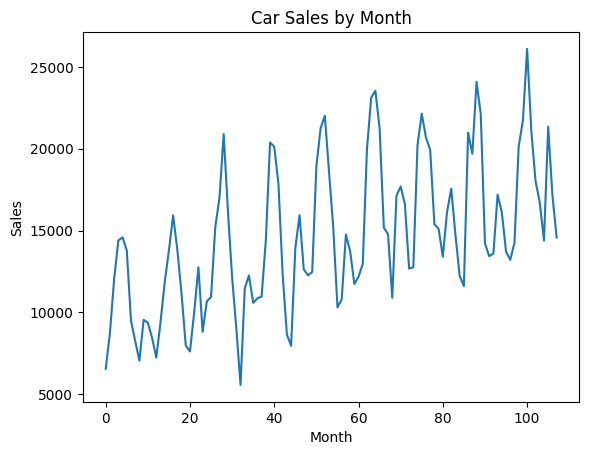

In [57]:
from matplotlib import pyplot as plt
plt.plot(carsales['period'],carsales['sales'])
plt.title('Car Sales by Month')
plt.xlabel('Month')
plt.ylabel('Sales')
plt.show()

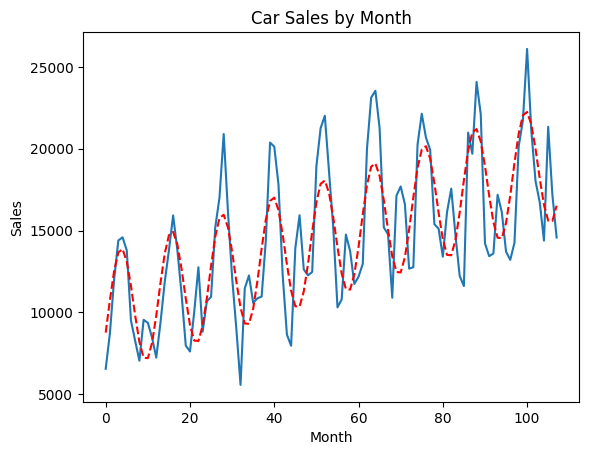

In [58]:
import math
carsales['sin_period']=carsales['period'].apply(lambda x: math.sin(x*2*math.pi/12))
carsales['cos_period']=carsales['period'].apply(lambda x: math.cos(x*2*math.pi/12))

x_trig = carsales.loc[:,['period','sin_period','cos_period']].values.reshape(-1,3)
y = carsales['sales'].values.reshape(-1,1)

regressor_trig = LinearRegression()
regressor_trig.fit(x_trig, y)

plt.plot(carsales['period'],carsales['sales'])
plt.plot(x,regressor_trig.predict(x_trig),'r--')
plt.title('Car Sales by Month')
plt.xlabel('Month')
plt.ylabel('Sales')
plt.show()

In [59]:
trig_line=regressor_trig.predict(x_trig)[:, 0]
print(get_rmse(trig_line,saleslist))

2680.5520744410464


9: Choosing the Best Regression to Use for Forecasting

In [60]:
carsales['squareroot']=carsales['period'].apply(lambda x: x**0.5)
carsales['exponent15']=carsales['period'].apply(lambda x: x**1.5)
carsales['log']=carsales['period'].apply(lambda x: math.log(x+1))

x_complex = carsales.loc[:,['period','log','sin_period','cos_period',
    'squareroot','exponent15','log','quadratic', 'cubic']].values.reshape(-1,9)
y = carsales['sales'].values.reshape(-1,1)

regressor_complex = LinearRegression()
regressor_complex.fit(x_complex,y)

complex_line=[prediction for sublist in regressor_complex.predict(x_complex)
    for prediction in sublist]
print(get_rmse(complex_line,saleslist))

2610.3938122978843


In [61]:
x_complex_train = carsales.loc[0:80,['period','log','sin_period','cos_period','squareroot',
    'exponent15','log','quadratic','cubic']].values.reshape(-1,9)
y_train = carsales.loc[0:80,'sales'].values.reshape(-1,1)

x_complex_test = carsales.loc[81:107,['period','log','sin_period','cos_period','squareroot',
    'exponent15','log','quadratic','cubic']].values.reshape(-1,9)
y_test = carsales.loc[81:107,'sales'].values.reshape(-1,1)

regressor_complex.fit(x_complex_train, y_train)

LinearRegression()

In [62]:
x_train = carsales.loc[0:80,['period']].values.reshape(-1,1)
x_test = carsales.loc[81:107,['period']].values.reshape(-1,1)
x_trig_train = carsales.loc[0:80,['period','sin_period','cos_period']].values.reshape(-1,3)
x_trig_test = carsales.loc[81:107,['period','sin_period','cos_period']].values.reshape(-1,3)

regressor.fit(x_train, y_train)
regressor_trig.fit(x_trig_train, y_train)

complex_test_predictions=[prediction for sublist in
      regressor_complex.predict(x_complex_test) for prediction in sublist]
test_predictions=[prediction for sublist in regressor.predict(x_test) for
      prediction in sublist]
trig_test_predictions=[prediction for sublist in
      regressor_trig.predict(x_trig_test) for prediction in sublist]

print(get_rmse(test_predictions,saleslist[81:107]))
print(get_rmse(trig_test_predictions,saleslist[81:107]))
print(get_rmse(complex_test_predictions,saleslist[81:107]))

4115.614379193304
3461.0823292599357
6006.013164062921
